In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
import os

dataset_path = "/content/drive/MyDrive/DAiSEE/DAiSEE/DataSet"

print(os.path.exists(dataset_path))
print(os.listdir(dataset_path)[:10])

True
['Test.txt', 'Train.txt', 'Validation.txt', 'Train']


In [13]:
import cv2
import os
import random

# Ambil semua video dari folder Train
video_files = []

for root, dirs, files in os.walk(os.path.join(dataset_path, "Train")):
    for file in files:
        if file.endswith(".avi"):
            video_files.append(os.path.join(root, file))

print("Total video:", len(video_files))

Total video: 929


In [14]:
import random

random.seed(42)

selected_videos = random.sample(video_files, 10)

print("10 video terpilih:")
for v in selected_videos:
    print(os.path.basename(v))

10 video terpilih:
1100072058.avi
4140810233.avi
2100572021.avi
1100151057.avi
1100111013.avi
3422270269.avi
3422270127.avi
4140810132.avi
1100152070.avi
4140810225.avi


In [15]:
#Folder Output

import cv2
import os

output_frames = "results/frames"
os.makedirs(output_frames, exist_ok=True)

frame_info = []

In [16]:
#Ekstra Frame

for i, video_path in enumerate(selected_videos, start=1):
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    frame_number = total_frames // 2
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

    ret, frame = cap.read()

    if ret:
        frame_name = f"video_{i:02d}.jpg"
        frame_path = os.path.join(output_frames, frame_name)

        cv2.imwrite(frame_path, frame)

        frame_info.append({
            "video": os.path.basename(video_path),
            "frame": frame_number,
            "fps": fps,
            "total_frames": total_frames,
            "output": frame_path
        })

    cap.release()

print("Ekstraksi selesai!")

Ekstraksi selesai!


In [17]:
print("Berhasil ekstrak:", len(frame_info), "frame")

for info in frame_info:
    print(info["output"])

Berhasil ekstrak: 10 frame
results/frames/video_01.jpg
results/frames/video_02.jpg
results/frames/video_03.jpg
results/frames/video_04.jpg
results/frames/video_05.jpg
results/frames/video_06.jpg
results/frames/video_07.jpg
results/frames/video_08.jpg
results/frames/video_09.jpg
results/frames/video_10.jpg


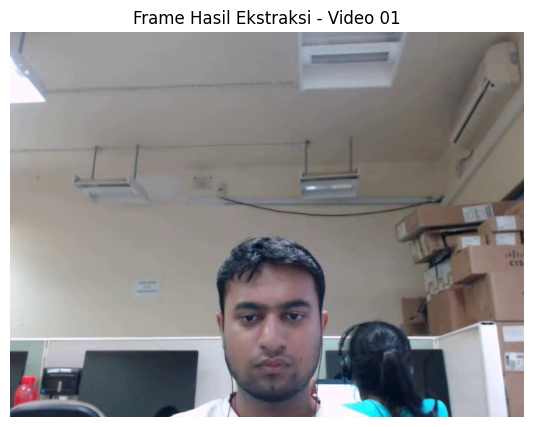

In [109]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("results/frames/video_01.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.title("Frame Hasil Ekstraksi - Video 01")
plt.axis("off")
plt.show()

In [18]:
import cv2
import os
import numpy as np

from glob import glob

augmentation_path = "results/augmentation"
os.makedirs(augmentation_path, exist_ok=True)

frame_paths = sorted(glob("results/frames/*.jpg"))

print("Jumlah frame:", len(frame_paths))

Jumlah frame: 10


In [19]:
#Horizontal Flip
flip_dir = os.path.join(augmentation_path, "horizontal_flip")
os.makedirs(flip_dir, exist_ok=True)

for path in frame_paths:
    img = cv2.imread(path)
    flipped = cv2.flip(img, 1)

    name = os.path.basename(path)
    cv2.imwrite(os.path.join(flip_dir, name), flipped)

print("Horizontal flip selesai")

Horizontal flip selesai


In [20]:
#Rotation

rotation_dir = os.path.join(augmentation_path, "rotation")
os.makedirs(rotation_dir, exist_ok=True)

for path in frame_paths:
    img = cv2.imread(path)
    h, w = img.shape[:2]

    matrix = cv2.getRotationMatrix2D((w/2, h/2), 15, 1)
    rotated = cv2.warpAffine(img, matrix, (w, h))

    name = os.path.basename(path)
    cv2.imwrite(os.path.join(rotation_dir, name), rotated)

print("Rotation selesai")

Rotation selesai


In [21]:
#Brightness Adjustment

brightness_dir = os.path.join(augmentation_path, "brightness")
os.makedirs(brightness_dir, exist_ok=True)

for path in frame_paths:
    img = cv2.imread(path)
    bright = cv2.convertScaleAbs(img, alpha=1.2, beta=30)

    name = os.path.basename(path)
    cv2.imwrite(os.path.join(brightness_dir, name), bright)

print("Brightness adjustment selesai")

Brightness adjustment selesai


In [22]:
#Gaussian Blur

blur_dir = os.path.join(augmentation_path, "gaussian_blur")
os.makedirs(blur_dir, exist_ok=True)

for path in frame_paths:
    img = cv2.imread(path)
    blurred = cv2.GaussianBlur(img, (5, 5), 0)

    name = os.path.basename(path)
    cv2.imwrite(os.path.join(blur_dir, name), blurred)

print("Gaussian blur selesai")

Gaussian blur selesai


In [23]:
#Zoom

zoom_dir = os.path.join(augmentation_path, "zoom")
os.makedirs(zoom_dir, exist_ok=True)

for path in frame_paths:
    img = cv2.imread(path)
    h, w = img.shape[:2]

    cropped = img[int(h*0.1):int(h*0.9), int(w*0.1):int(w*0.9)]
    zoomed = cv2.resize(cropped, (w, h))

    name = os.path.basename(path)
    cv2.imwrite(os.path.join(zoom_dir, name), zoomed)

print("Zoom selesai")

Zoom selesai


In [24]:
import matplotlib.pyplot as plt
import cv2

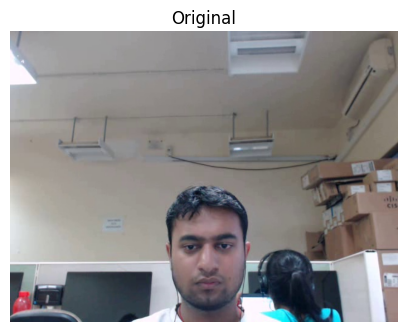

In [25]:
sample = "video_01.jpg"

original = cv2.imread(f"results/frames/{sample}")
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(original)
plt.title("Original")
plt.axis("off")
plt.show()

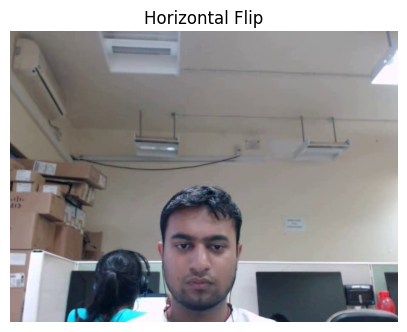

In [26]:
img = cv2.imread("results/augmentation/horizontal_flip/video_01.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.title("Horizontal Flip")
plt.axis("off")
plt.show()

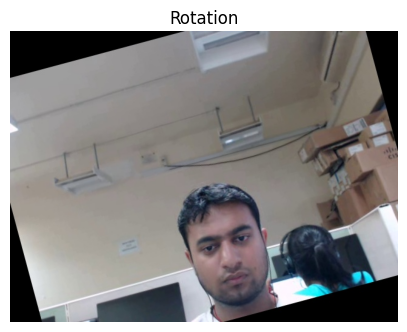

In [27]:
img = cv2.imread("results/augmentation/rotation/video_01.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.title("Rotation")
plt.axis("off")
plt.show()

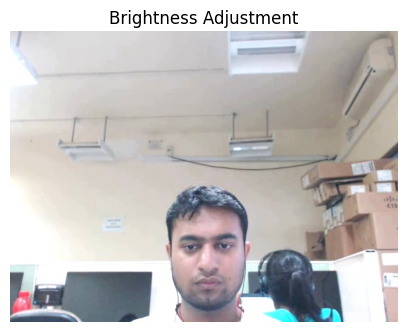

In [28]:
img = cv2.imread("results/augmentation/brightness/video_01.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.title("Brightness Adjustment")
plt.axis("off")
plt.show()

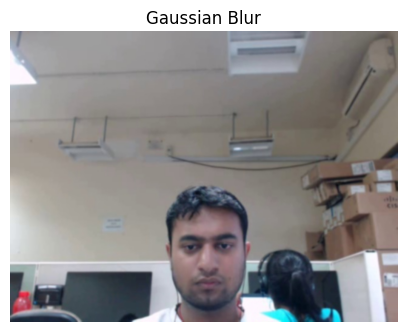

In [29]:
img = cv2.imread("results/augmentation/gaussian_blur/video_01.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

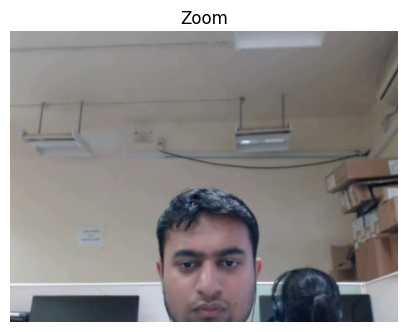

In [30]:
img = cv2.imread("results/augmentation/zoom/video_01.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.title("Zoom")
plt.axis("off")
plt.show()

In [12]:
import cv2
import os

video_path = os.path.join(dataset_path, "Train")
print("Jumlah folder peserta:", len(os.listdir(video_path)))

Jumlah folder peserta: 46


In [31]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import random
import time

from PIL import Image, ImageEnhance, ImageDraw, ImageFont
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

In [32]:
import os

os.makedirs("data/frames", exist_ok=True)
os.makedirs("results/augmentation", exist_ok=True)

print("Folder berhasil dibuat")

Folder berhasil dibuat


In [33]:
!pip install pillow numpy pandas matplotlib scikit-image cairosvg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [cairosvg]


In [34]:
import cairosvg

os.makedirs("data/compression", exist_ok=True)
os.makedirs("results/compression", exist_ok=True)

print("Folder compression berhasil dibuat")

Folder compression berhasil dibuat


In [35]:
#BAGIAN B

from PIL import Image, ImageDraw

img = Image.new("RGB", (512, 512), (235, 240, 245))
draw = ImageDraw.Draw(img)

# Background
draw.rectangle((0, 330, 512, 512), fill=(90, 150, 95))
draw.ellipse((320, 40, 450, 170), fill=(255, 210, 70))

# House
draw.rectangle((80, 220, 250, 390), fill=(180, 95, 70))
draw.polygon(
    [(50, 220), (165, 130), (280, 220)],
    fill=(130, 55, 45)
)
draw.rectangle((130, 270, 200, 390), fill=(90, 60, 45))

# Windows
draw.rectangle((100, 250, 130, 290), fill=(170, 210, 235))
draw.rectangle((200, 250, 230, 290), fill=(170, 210, 235))

# Save image in different formats
img.save("data/compression/sample.bmp")
img.save("data/compression/sample.jpg", quality=90)
img.save("data/compression/sample.png")

# Create SVG
svg_content = """
<svg xmlns="http://www.w3.org/2000/svg"
width="512" height="512">
<rect width="512" height="512" fill="#eaf0f5"/>
<circle cx="385" cy="105" r="65" fill="#ffd246"/>
<rect x="80" y="220" width="170" height="170" fill="#b45f46"/>
<polygon points="50,220 165,130 280,220" fill="#82372d"/>
<rect y="330" width="512" height="182" fill="#5a965f"/>
</svg>
"""

with open("data/compression/sample.svg", "w") as f:
    f.write(svg_content)

print("Dataset berhasil dibuat!")

Dataset berhasil dibuat!


In [36]:
from PIL import Image, ImageDraw

img = Image.new("RGB", (512, 512), (235, 240, 245))
draw = ImageDraw.Draw(img)

# Background
draw.rectangle(
    (0, 330, 512, 512),
    fill=(90, 150, 95)
)

# Sun
draw.ellipse(
    (320, 40, 450, 170),
    fill=(255, 210, 70)
)

print("Background berhasil dibuat")

Background berhasil dibuat


In [37]:
# House body
draw.rectangle(
    (80, 220, 250, 390),
    fill=(180, 95, 70)
)

# Roof
draw.polygon(
    [(50, 220), (165, 130), (280, 220)],
    fill=(130, 55, 45)
)

# Door
draw.rectangle(
    (130, 270, 200, 390),
    fill=(90, 60, 45)
)

# Windows
draw.rectangle(
    (100, 250, 130, 290),
    fill=(170, 210, 235)
)

draw.rectangle(
    (200, 250, 230, 290),
    fill=(170, 210, 235)
)

print("Rumah berhasil dibuat")

Rumah berhasil dibuat


In [38]:
img.save("data/compression/sample.bmp")
img.save("data/compression/sample.jpg", quality=90)
img.save("data/compression/sample.png")

print("BMP, JPEG, dan PNG berhasil dibuat")

BMP, JPEG, dan PNG berhasil dibuat


In [39]:
svg_content = """
<svg xmlns="http://www.w3.org/2000/svg"
width="512" height="512">

<rect width="512" height="512" fill="#eaf0f5"/>

<circle cx="385" cy="105" r="65" fill="#ffd246"/>

<rect x="80" y="220" width="170" height="170"
fill="#b45f46"/>

<polygon points="50,220 165,130 280,220"
fill="#82372d"/>

<rect y="330" width="512" height="182"
fill="#5a965f"/>

</svg>
"""

with open("data/compression/sample.svg", "w") as f:
    f.write(svg_content)

print("SVG berhasil dibuat")

SVG berhasil dibuat


In [40]:
import cairosvg

cairosvg.svg2png(
    url="data/compression/sample.svg",
    write_to="data/compression/sample_from_svg.png",
    output_width=512,
    output_height=512
)

print("SVG berhasil dikonversi")

SVG berhasil dikonversi


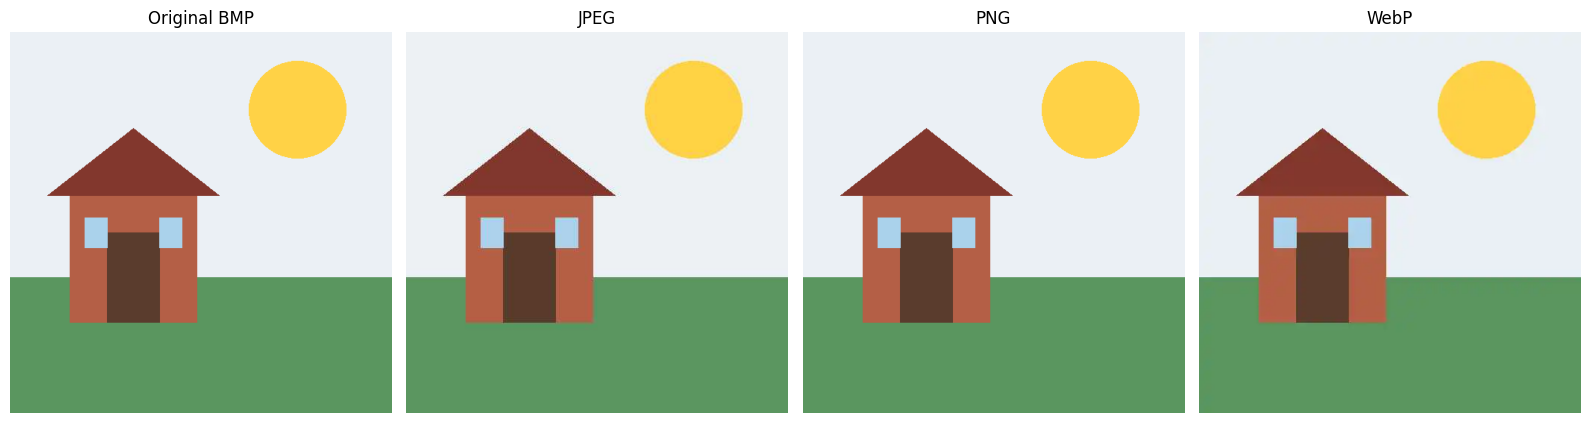

In [111]:
import cv2
import matplotlib.pyplot as plt

paths = [
    "data/compression/sample.bmp",
    "results/compression/jpeg/sample.jpg",
    "results/compression/png/sample.png",
    "results/compression/webp/sample.webp"
]

labels = ["Original BMP", "JPEG", "PNG", "WebP"]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, path, label in zip(axes, paths, labels):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
import os
import time
import pandas as pd
import numpy as np
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

os.makedirs("results/compression/jpeg", exist_ok=True)
os.makedirs("results/compression/png", exist_ok=True)
os.makedirs("results/compression/webp", exist_ok=True)

print("Library dan folder kompresi siap")

Library dan folder kompresi siap


In [43]:
def compress_jpeg(image, output_path, quality=50):
    start = time.time()

    image.convert("RGB").save(
        output_path,
        format="JPEG",
        quality=quality,
        optimize=True
    )

    return time.time() - start

In [44]:
def compress_png(image, output_path):
    start = time.time()

    image.save(
        output_path,
        format="PNG",
        optimize=True
    )

    return time.time() - start

In [45]:
def compress_webp(image, output_path, quality=50):
    start = time.time()

    image.convert("RGB").save(
        output_path,
        format="WEBP",
        quality=quality,
        method=6
    )

    return time.time() - start

In [46]:
image = Image.open("data/compression/sample.bmp")

jpeg_time = compress_jpeg(
    image,
    "results/compression/jpeg/sample.jpg",
    quality=50
)

print("Kompresi JPEG berhasil")
print("Waktu kompresi:", jpeg_time, "detik")

Kompresi JPEG berhasil
Waktu kompresi: 0.005061149597167969 detik


In [47]:
original_size = os.path.getsize("data/compression/sample.bmp")
jpeg_size = os.path.getsize("results/compression/jpeg/sample.jpg")

print("Ukuran asli:", original_size, "bytes")
print("Ukuran JPEG:", jpeg_size, "bytes")

Ukuran asli: 786486 bytes
Ukuran JPEG: 5557 bytes


In [48]:
compression_ratio = original_size / jpeg_size

space_saving = (
    1 - jpeg_size / original_size
) * 100

print("Compression Ratio:", round(compression_ratio, 2), ":1")
print("Space Saving:", round(space_saving, 2), "%")

Compression Ratio: 141.53 :1
Space Saving: 99.29 %


In [49]:
original = np.array(image.convert("RGB"))

compressed = np.array(
    Image.open("results/compression/jpeg/sample.jpg").convert("RGB")
)

psnr_jpeg = peak_signal_noise_ratio(
    original, compressed, data_range=255
)

ssim_jpeg = structural_similarity(
    original, compressed,
    channel_axis=-1,
    data_range=255
)

print("PSNR JPEG:", round(psnr_jpeg, 2), "dB")
print("SSIM JPEG:", round(ssim_jpeg, 4))

PSNR JPEG: 35.5 dB
SSIM JPEG: 0.9679


In [50]:
image_png = Image.open("data/compression/sample.bmp")

png_time = compress_png(
    image_png,
    "results/compression/png/sample.png"
)

print("Kompresi PNG berhasil")
print("Waktu kompresi:", png_time, "detik")

Kompresi PNG berhasil
Waktu kompresi: 0.019827604293823242 detik


In [51]:
png_size = os.path.getsize(
    "results/compression/png/sample.png"
)

print("Ukuran BMP asli:", original_size, "bytes")
print("Ukuran PNG:", png_size, "bytes")

Ukuran BMP asli: 786486 bytes
Ukuran PNG: 2334 bytes


In [52]:
png_ratio = original_size / png_size

png_saving = (
    1 - png_size / original_size
) * 100

print("Compression Ratio PNG:", round(png_ratio, 2), ":1")
print("Space Saving PNG:", round(png_saving, 2), "%")

Compression Ratio PNG: 336.97 :1
Space Saving PNG: 99.7 %


In [53]:
original_png = np.array(
    image_png.convert("RGB")
)

compressed_png = np.array(
    Image.open(
        "results/compression/png/sample.png"
    ).convert("RGB")
)

psnr_png = peak_signal_noise_ratio(
    original_png,
    compressed_png,
    data_range=255
)

ssim_png = structural_similarity(
    original_png,
    compressed_png,
    channel_axis=-1,
    data_range=255
)

print("PSNR PNG:", psnr_png)
print("SSIM PNG:", ssim_png)

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


PSNR PNG: inf
SSIM PNG: 1.0


In [54]:
image_webp = Image.open("data/compression/sample.bmp")

webp_time = compress_webp(
    image_webp,
    "results/compression/webp/sample.webp",
    quality=50
)

print("Kompresi WebP berhasil")
print("Waktu kompresi:", webp_time, "detik")

Kompresi WebP berhasil
Waktu kompresi: 0.277449369430542 detik


In [55]:
webp_size = os.path.getsize(
    "results/compression/webp/sample.webp"
)

print("Ukuran BMP asli:", original_size, "bytes")
print("Ukuran WebP:", webp_size, "bytes")

Ukuran BMP asli: 786486 bytes
Ukuran WebP: 2480 bytes


In [56]:
webp_ratio = original_size / webp_size

webp_saving = (
    1 - webp_size / original_size
) * 100

print("Compression Ratio WebP:", round(webp_ratio, 2), ":1")
print("Space Saving WebP:", round(webp_saving, 2), "%")

Compression Ratio WebP: 317.13 :1
Space Saving WebP: 99.68 %


In [57]:
original_webp = np.array(
    image_webp.convert("RGB")
)

compressed_webp = np.array(
    Image.open(
        "results/compression/webp/sample.webp"
    ).convert("RGB")
)

psnr_webp = peak_signal_noise_ratio(
    original_webp,
    compressed_webp,
    data_range=255
)

print("PSNR WebP:", round(psnr_webp, 2), "dB")

PSNR WebP: 37.73 dB


In [58]:
ssim_webp = structural_similarity(
    original_webp,
    compressed_webp,
    channel_axis=-1,
    data_range=255
)

print("SSIM WebP:", round(ssim_webp, 4))

SSIM WebP: 0.9805


In [59]:
jpeg_ratio = compression_ratio
jpeg_saving = space_saving

png_ratio = original_size / png_size
png_saving = (1 - png_size / original_size) * 100

webp_ratio = original_size / webp_size
webp_saving = (1 - webp_size / original_size) * 100

print("Variabel berhasil disesuaikan")

Variabel berhasil disesuaikan


In [112]:

compression_results = pd.DataFrame({
    "Teknik": ["JPEG", "PNG", "WebP"],
    "Ukuran (bytes)": [
        jpeg_size, png_size, webp_size
    ],
    "Compression Ratio": [
        jpeg_ratio, png_ratio, webp_ratio
    ],
    "Space Saving (%)": [
        jpeg_saving, png_saving, webp_saving
    ],
    "PSNR (dB)": [
        psnr_jpeg, psnr_png, psnr_webp
    ],
    "SSIM": [
        ssim_jpeg, ssim_png, ssim_webp
    ],
    "Waktu (detik)": [
        jpeg_time, png_time, webp_time
    ]
})

compression_results.round(4)


,Teknik,Ukuran (bytes),Compression Ratio,Space Saving (%),PSNR (dB),SSIM,Waktu (detik)
0,JPEG,5557,141.5307,99.2934,35.4953,0.9679,0.0051
1,PNG,2334,336.9692,99.7032,inf,1.0000,0.0198
2,WebP,2480,317.1315,99.6847,37.7299,0.9805,0.2774


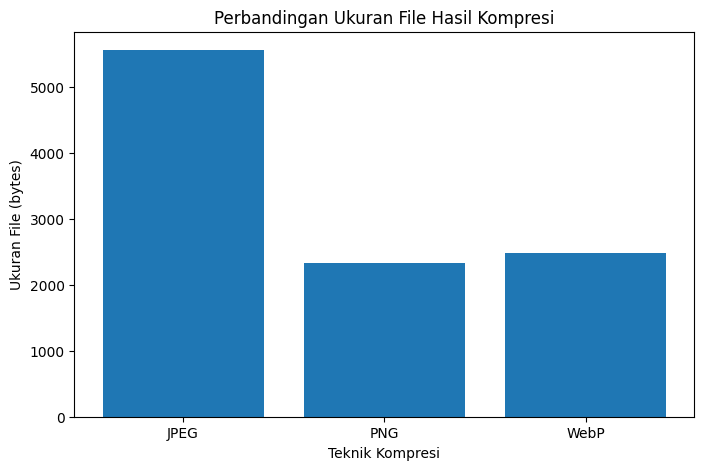

In [61]:
plt.figure(figsize=(8, 5))

plt.bar(
    compression_results["Teknik"],
    compression_results["Ukuran (bytes)"]
)

plt.title("Perbandingan Ukuran File Hasil Kompresi")
plt.xlabel("Teknik Kompresi")
plt.ylabel("Ukuran File (bytes)")

plt.show()

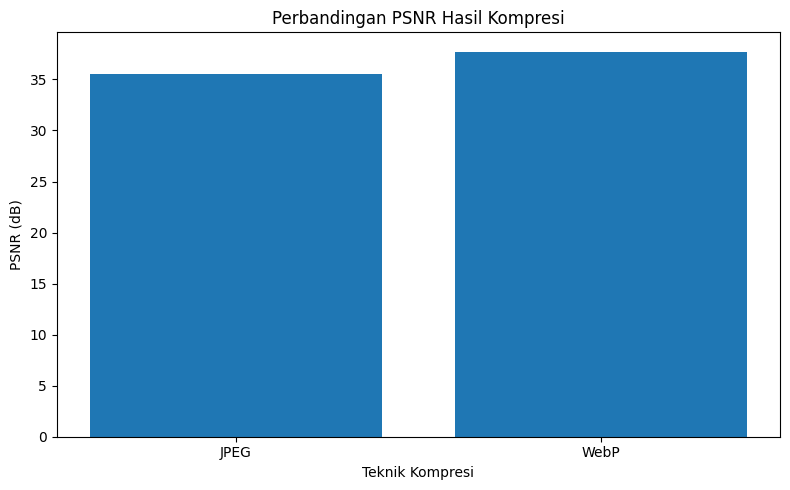

In [113]:

import matplotlib.pyplot as plt

format_kompresi = ["JPEG", "WebP"]
nilai_psnr = [35.50, 37.73]

plt.figure(figsize=(8, 5))
plt.bar(format_kompresi, nilai_psnr)

plt.title("Perbandingan PSNR Hasil Kompresi")
plt.xlabel("Teknik Kompresi")
plt.ylabel("PSNR (dB)")

plt.tight_layout()
plt.show()

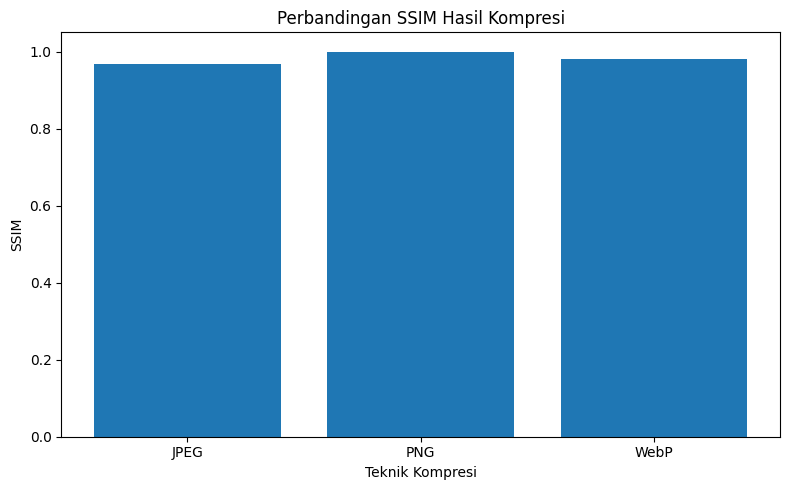

In [114]:

import matplotlib.pyplot as plt

format_kompresi = ["JPEG", "PNG", "WebP"]
nilai_ssim = [0.9679, 1.0000, 0.9805]

plt.figure(figsize=(8, 5))
plt.bar(format_kompresi, nilai_ssim)

plt.title("Perbandingan SSIM Hasil Kompresi")
plt.xlabel("Teknik Kompresi")
plt.ylabel("SSIM")

plt.tight_layout()
plt.show()


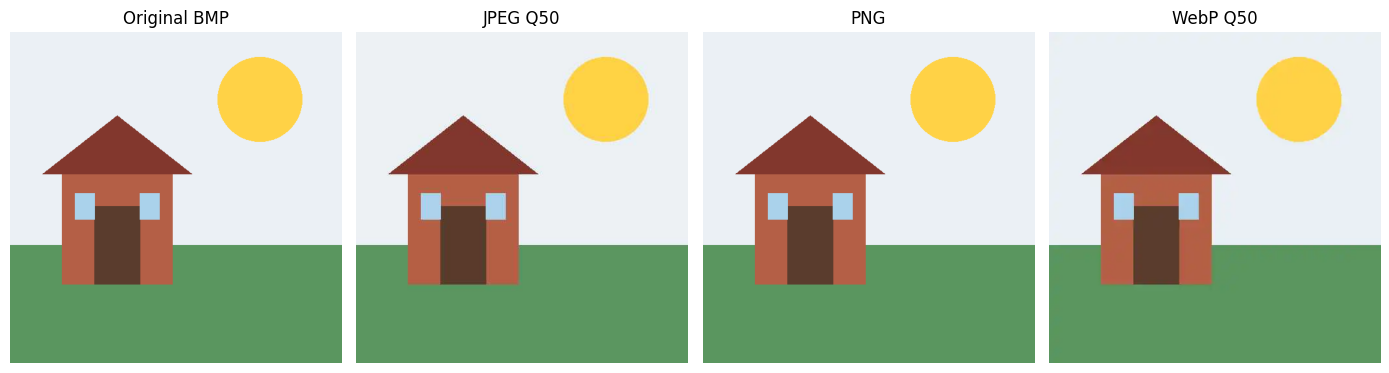

In [62]:
original = Image.open(
    "data/compression/sample.bmp"
).convert("RGB")

jpeg_img = Image.open(
    "results/compression/jpeg/sample.jpg"
)

png_img = Image.open(
    "results/compression/png/sample.png"
)

webp_img = Image.open(
    "results/compression/webp/sample.webp"
)

images = [
    original,
    jpeg_img,
    png_img,
    webp_img
]

titles = [
    "Original BMP",
    "JPEG Q50",
    "PNG",
    "WebP Q50"
]

plt.figure(figsize=(14, 5))

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [63]:
input_files = [
    "sample.bmp",
    "sample.jpg",
    "sample.png",
    "sample.svg"
]

print("Jumlah input gambar:", len(input_files))

Jumlah input gambar: 4


In [64]:
input_sizes = {}

for file in input_files:
    path = f"data/compression/{file}"
    input_sizes[file] = os.path.getsize(path)

input_sizes

{'sample.bmp': 786486,
 'sample.jpg': 12941,
 'sample.png': 3174,
 'sample.svg': 355}

In [65]:
cairosvg.svg2png(
    url="data/compression/sample.svg",
    write_to="data/compression/sample_rasterized.png",
    output_width=512,
    output_height=512
)

print("SVG berhasil dirasterisasi menjadi PNG")

SVG berhasil dirasterisasi menjadi PNG


In [66]:
raster_inputs = {
    "BMP": "data/compression/sample.bmp",
    "JPEG": "data/compression/sample.jpg",
    "PNG": "data/compression/sample.png",
    "SVG_rasterized": "data/compression/sample_rasterized.png"
}

print("Input raster siap diuji")

Input raster siap diuji


In [67]:
for technique in ["JPEG", "PNG", "WebP"]:
    os.makedirs(
        f"results/compression/{technique}",
        exist_ok=True
    )

print("Folder hasil kompresi siap")

Folder hasil kompresi siap


In [68]:
jpeg_batch_results = []

for name, path in raster_inputs.items():
    img = Image.open(path).convert("RGB")

    output_path = f"results/compression/JPEG/{name}.jpg"

    elapsed = compress_jpeg(
        img,
        output_path,
        quality=50
    )

    size = os.path.getsize(output_path)

    jpeg_batch_results.append({
        "Input": name,
        "Output Size (bytes)": size,
        "Time (seconds)": elapsed
    })

print("Batch JPEG selesai")

Batch JPEG selesai


In [69]:
png_batch_results = []

for name, path in raster_inputs.items():
    img = Image.open(path)

    output_path = f"results/compression/PNG/{name}.png"

    elapsed = compress_png(
        img,
        output_path
    )

    size = os.path.getsize(output_path)

    png_batch_results.append({
        "Input": name,
        "Output Size (bytes)": size,
        "Time (seconds)": elapsed
    })

print("Batch PNG selesai")

Batch PNG selesai


In [70]:
webp_batch_results = []

for name, path in raster_inputs.items():
    img = Image.open(path).convert("RGB")
    output_path = f"results/compression/WebP/{name}.webp"

    elapsed = compress_webp(img, output_path, quality=50)
    size = os.path.getsize(output_path)

    webp_batch_results.append({
        "Input": name,
        "Output Size (bytes)": size,
        "Time (seconds)": elapsed
    })

print("Batch WebP selesai")

Batch WebP selesai


In [71]:
all_batch_results = []

for method, results in [
    ("JPEG", jpeg_batch_results),
    ("PNG", png_batch_results),
    ("WebP", webp_batch_results)
]:
    for row in results:
        all_batch_results.append({
            "Method": method,
            "Input": row["Input"],
            "Output Size (bytes)": row["Output Size (bytes)"],
            "Time (seconds)": row["Time (seconds)"]
        })

batch_df = pd.DataFrame(all_batch_results)

batch_df

,Method,Input,Output Size (bytes),Time (seconds)
0,JPEG,BMP,5557,0.003140
1,JPEG,JPEG,5552,0.002593
2,JPEG,PNG,5557,0.002593
3,JPEG,SVG_rasterized,4406,0.002465
4,PNG,BMP,2334,0.017616
5,PNG,JPEG,33585,0.051421
6,PNG,PNG,2334,0.018747
7,PNG,SVG_rasterized,5226,0.022695
8,WebP,BMP,2480,0.038137
9,WebP,JPEG,2324,0.022971


In [72]:
original_sizes = {
    name: os.path.getsize(path)
    for name, path in raster_inputs.items()
}

batch_df["Original Size (bytes)"] = batch_df["Input"].map(original_sizes)

batch_df["Compression Ratio"] = (
    batch_df["Original Size (bytes)"] /
    batch_df["Output Size (bytes)"]
)

batch_df["Space Saving (%)"] = (
    1 - batch_df["Output Size (bytes)"] /
    batch_df["Original Size (bytes)"]
) * 100

batch_df

,Method,Input,Output Size (bytes),Time (seconds),Original Size (bytes),Compression Ratio,Space Saving (%)
0,JPEG,BMP,5557,0.003140,786486,141.530682,99.293439
1,JPEG,JPEG,5552,0.002593,12941,2.330872,57.097597
2,JPEG,PNG,5557,0.002593,3174,0.571171,-75.078765
3,JPEG,SVG_rasterized,4406,0.002465,5972,1.355424,26.222371
4,PNG,BMP,2334,0.017616,786486,336.969152,99.703237
5,PNG,JPEG,33585,0.051421,12941,0.385321,-159.523994
6,PNG,PNG,2334,0.018747,3174,1.359897,26.465028
7,PNG,SVG_rasterized,5226,0.022695,5972,1.142748,12.491628
8,WebP,BMP,2480,0.038137,786486,317.131452,99.684673
9,WebP,JPEG,2324,0.022971,12941,5.568417,82.041573


In [73]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

quality_results = []

for method in ["JPEG", "PNG", "WebP"]:
    for name, path in raster_inputs.items():

        original = np.array(Image.open(path).convert("RGB"))

        if method == "JPEG":
            output_path = f"results/compression/JPEG/{name}.jpg"
        elif method == "PNG":
            output_path = f"results/compression/PNG/{name}.png"
        else:
            output_path = f"results/compression/WebP/{name}.webp"

        compressed = np.array(Image.open(output_path).convert("RGB"))

        psnr = peak_signal_noise_ratio(
            original, compressed, data_range=255
        )

        ssim = structural_similarity(
            original, compressed, channel_axis=2, data_range=255
        )

        quality_results.append({
            "Method": method,
            "Input": name,
            "PSNR (dB)": psnr,
            "SSIM": ssim
        })

quality_df = pd.DataFrame(quality_results)
quality_df

/usr/local/lib/python3.13/dist-packages/skimage/metrics/simple_metrics.py:168: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


,Method,Input,PSNR (dB),SSIM
0,JPEG,BMP,35.495263,0.967949
1,JPEG,JPEG,38.375515,0.975684
2,JPEG,PNG,35.495263,0.967949
3,JPEG,SVG_rasterized,37.649419,0.980781
4,PNG,BMP,inf,1.000000
5,PNG,JPEG,inf,1.000000
6,PNG,PNG,inf,1.000000
7,PNG,SVG_rasterized,inf,1.000000
8,WebP,BMP,37.729900,0.980484
9,WebP,JPEG,40.739086,0.983453


In [74]:
final_df = pd.merge(
    batch_df,
    quality_df,
    on=["Method", "Input"]
)

final_df = final_df[
    [
        "Method",
        "Input",
        "Original Size (bytes)",
        "Output Size (bytes)",
        "Compression Ratio",
        "Space Saving (%)",
        "PSNR (dB)",
        "SSIM",
        "Time (seconds)"
    ]
]

final_df.round(4)

,Method,Input,Original Size (bytes),Output Size (bytes),Compression Ratio,Space Saving (%),PSNR (dB),SSIM,Time (seconds)
0,JPEG,BMP,786486,5557,141.5307,99.2934,35.4953,0.9679,0.0031
1,JPEG,JPEG,12941,5552,2.3309,57.0976,38.3755,0.9757,0.0026
2,JPEG,PNG,3174,5557,0.5712,-75.0788,35.4953,0.9679,0.0026
3,JPEG,SVG_rasterized,5972,4406,1.3554,26.2224,37.6494,0.9808,0.0025
4,PNG,BMP,786486,2334,336.9692,99.7032,inf,1.0000,0.0176
5,PNG,JPEG,12941,33585,0.3853,-159.5240,inf,1.0000,0.0514
6,PNG,PNG,3174,2334,1.3599,26.4650,inf,1.0000,0.0187
7,PNG,SVG_rasterized,5972,5226,1.1427,12.4916,inf,1.0000,0.0227
8,WebP,BMP,786486,2480,317.1315,99.6847,37.7299,0.9805,0.0381
9,WebP,JPEG,12941,2324,5.5684,82.0416,40.7391,0.9835,0.0230


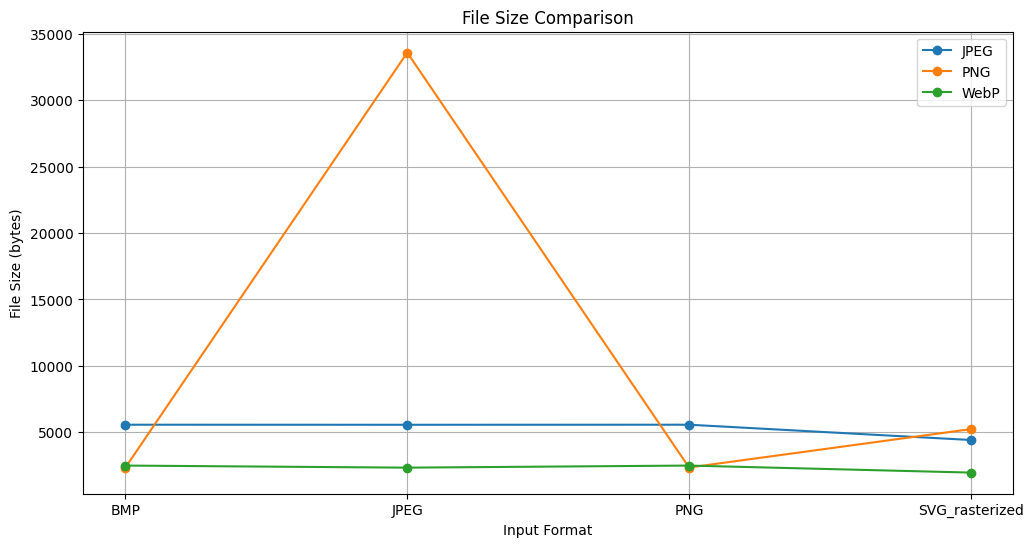

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for method in ["JPEG", "PNG", "WebP"]:
    subset = final_df[final_df["Method"] == method]
    plt.plot(
        subset["Input"],
        subset["Output Size (bytes)"],
        marker="o",
        label=method
    )

plt.ylabel("File Size (bytes)")
plt.xlabel("Input Format")
plt.title("File Size Comparison")
plt.legend()
plt.grid(True)
plt.show()

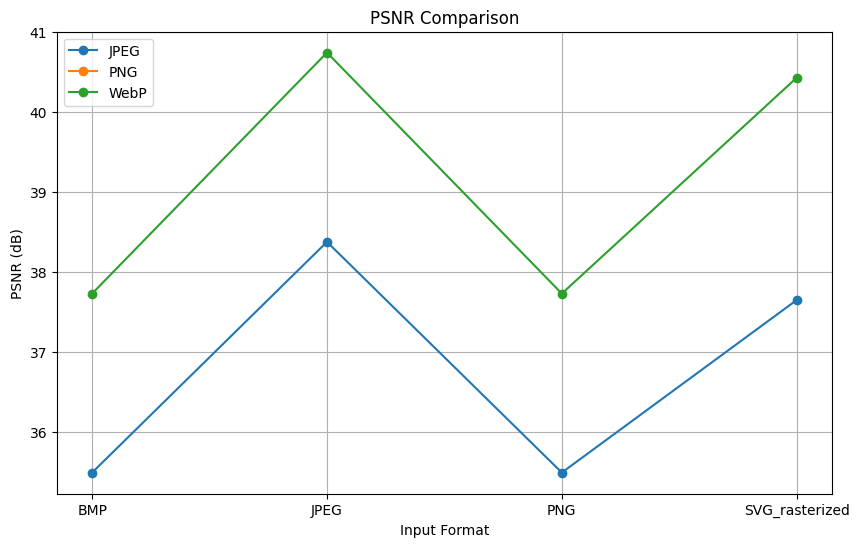

In [76]:
plt.figure(figsize=(10, 6))

for method in ["JPEG", "PNG", "WebP"]:
    subset = final_df[final_df["Method"] == method]
    plt.plot(
        subset["Input"],
        subset["PSNR (dB)"],
        marker="o",
        label=method
    )

plt.ylabel("PSNR (dB)")
plt.xlabel("Input Format")
plt.title("PSNR Comparison")
plt.legend()
plt.grid(True)
plt.show()

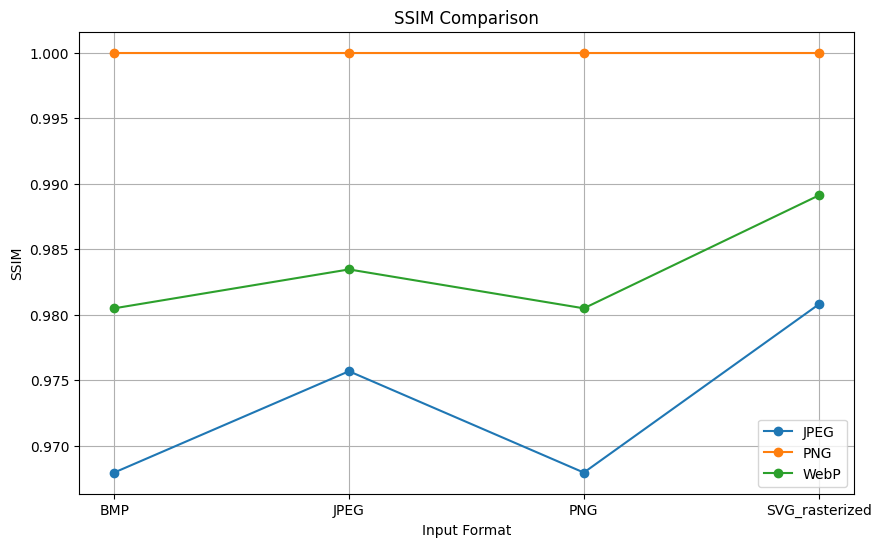

In [77]:
plt.figure(figsize=(10, 6))

for method in ["JPEG", "PNG", "WebP"]:
    subset = final_df[final_df["Method"] == method]
    plt.plot(
        subset["Input"],
        subset["SSIM"],
        marker="o",
        label=method
    )

plt.ylabel("SSIM")
plt.xlabel("Input Format")
plt.title("SSIM Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [78]:
#BAGIAN C

import os
from PIL import Image, ImageDraw, ImageFont

os.makedirs("results/watermark", exist_ok=True)

original_image = Image.open(
    "data/compression/sample.png"
).convert("RGB")

print("Ukuran gambar:", original_image.size)

Ukuran gambar: (512, 512)


In [79]:
watermarked = original_image.copy()

draw = ImageDraw.Draw(watermarked)

In [80]:
font = ImageFont.load_default()

text = "WATERMARK"

In [81]:
draw.text(
    (20, 20),
    text,
    fill=(255, 255, 255),
    font=font,
    stroke_width=2,
    stroke_fill=(0, 0, 0)
)

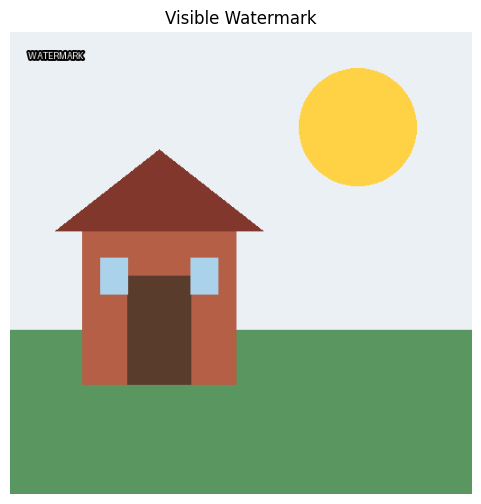

In [82]:
watermarked.save("results/watermark/visible_watermark.png")

plt.figure(figsize=(6, 6))
plt.imshow(watermarked)
plt.title("Visible Watermark")
plt.axis("off")
plt.show()

In [83]:
original_array = np.array(original_image)
watermarked_array = np.array(watermarked)

visible_psnr = peak_signal_noise_ratio(
    original_array,
    watermarked_array,
    data_range=255
)

visible_ssim = structural_similarity(
    original_array,
    watermarked_array,
    channel_axis=2,
    data_range=255
)

print("Visible Watermark PSNR:", visible_psnr)
print("Visible Watermark SSIM:", visible_ssim)

Visible Watermark PSNR: 27.60457641934796
Visible Watermark SSIM: 0.995062702653613


In [84]:
lsb_original = np.array(original_image).copy()

message = "WATERMARK"
binary_message = ''.join(
    format(ord(char), '08b') for char in message
)

print("Pesan:", message)
print("Jumlah bit:", len(binary_message))

Pesan: WATERMARK
Jumlah bit: 72


In [85]:
flat_pixels = lsb_original.reshape(-1)

for i, bit in enumerate(binary_message):
    flat_pixels[i] = (
        flat_pixels[i] & 254
    ) | int(bit)

lsb_watermarked = flat_pixels.reshape(lsb_original.shape)

lsb_image = Image.fromarray(lsb_watermarked.astype("uint8"))

lsb_image.save("results/watermark/invisible_watermark.png")

print("Invisible watermark berhasil disisipkan")

Invisible watermark berhasil disisipkan


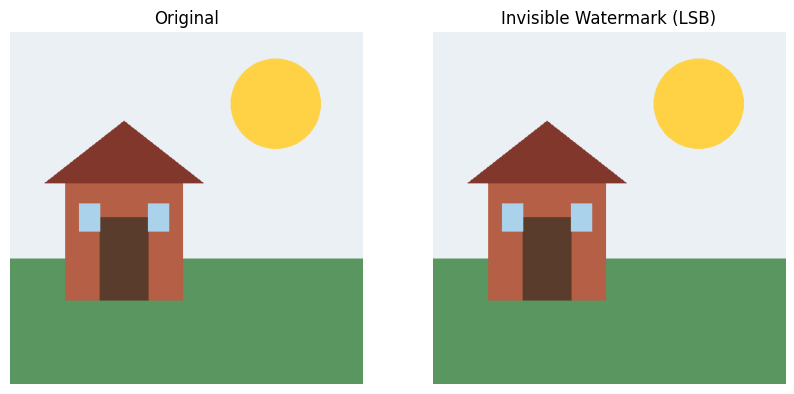

In [86]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lsb_image)
plt.title("Invisible Watermark (LSB)")
plt.axis("off")

plt.show()

In [87]:
extracted_bits = ""

for i in range(len(binary_message)):
    extracted_bits += str(
        lsb_watermarked.reshape(-1)[i] & 1
    )

extracted_message = ""

for i in range(0, len(extracted_bits), 8):
    byte = extracted_bits[i:i+8]
    extracted_message += chr(int(byte, 2))

print("Extracted message:", extracted_message)

Extracted message: WATERMARK


In [88]:
lsb_psnr = peak_signal_noise_ratio(
    original_array,
    lsb_watermarked,
    data_range=255
)

lsb_ssim = structural_similarity(
    original_array,
    lsb_watermarked,
    channel_axis=2,
    data_range=255
)

print("LSB PSNR:", lsb_psnr)
print("LSB SSIM:", lsb_ssim)

LSB PSNR: 91.64673493188958
LSB SSIM: 0.999999909743965


In [89]:
lsb_image.save(
    "results/watermark/lsb_attack.jpg",
    format="JPEG",
    quality=90
)

jpeg_attacked = np.array(
    Image.open("results/watermark/lsb_attack.jpg").convert("RGB")
)

print("JPEG attack selesai")

JPEG attack selesai


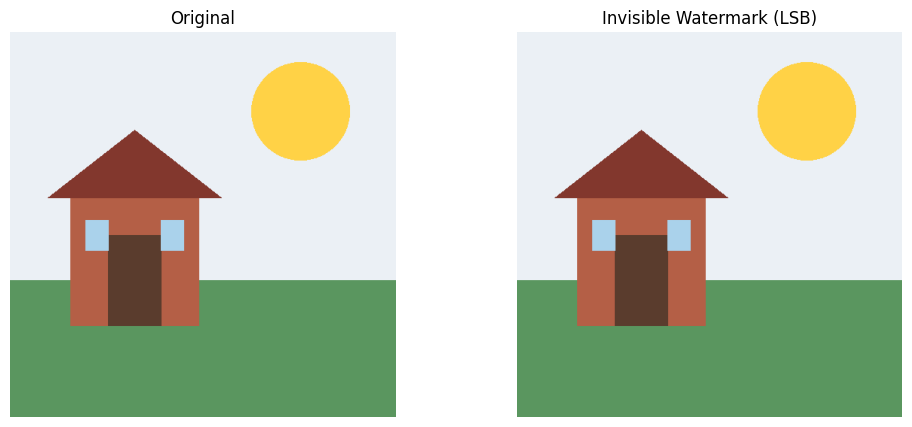

Pesan hasil ekstraksi: WATERMARK


In [119]:
import matplotlib.pyplot as plt
from PIL import Image

# Sesuaikan path dengan file hasil LSB di notebook
original = Image.open("data/compression/sample.bmp")
watermarked = Image.open("results/watermark/invisible_watermark.png")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(watermarked)
plt.title("Invisible Watermark (LSB)")
plt.axis("off")

plt.show()

print("Pesan hasil ekstraksi:", extracted_message)

In [90]:
attacked_bits = ""

for i in range(len(binary_message)):
    attacked_bits += str(
        jpeg_attacked.reshape(-1)[i] & 1
    )

attacked_message = ""

for i in range(0, len(attacked_bits), 8):
    byte = attacked_bits[i:i+8]
    attacked_message += chr(int(byte, 2))

print("Message after JPEG attack:", attacked_message)

Message after JPEG attack: I$I$I$


In [91]:
lsb_image.resize(
    (256, 256)
).save("results/watermark/lsb_resize.png")

resize_attacked = np.array(
    Image.open("results/watermark/lsb_resize.png").convert("RGB")
)

print("Resize attack selesai")

Resize attack selesai


In [92]:
resize_bits = ""

for i in range(len(binary_message)):
    resize_bits += str(resize_attacked.reshape(-1)[i] & 1)

resize_message = ""

for i in range(0, len(resize_bits), 8):
    resize_message += chr(int(resize_bits[i:i+8], 2))

print("Message after resize attack:", resize_message)

Message after resize attack: ¶Ûm¶Ûm¶Ûm


In [93]:
cropped = lsb_image.crop((56, 56, 456, 456)).resize((512, 512))

cropped.save("results/watermark/lsb_crop.png")

crop_attacked = np.array(cropped)

print("Crop attack selesai:", crop_attacked.shape)

Crop attack selesai: (512, 512, 3)


In [94]:
crop_bits = ""

for i in range(len(binary_message)):
    crop_bits += str(crop_attacked.reshape(-1)[i] & 1)

crop_message = ""

for i in range(0, len(crop_bits), 8):
    crop_message += chr(int(crop_bits[i:i+8], 2))

print("Message after crop attack:", crop_message)

Message after crop attack: ¶Ûm¶Ûm¶Ûm


In [95]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import pandas as pd
import numpy as np
from PIL import Image

In [96]:
original_array = np.array(original_image)

print("Original image shape:", original_array.shape)

Original image shape: (512, 512, 3)


In [97]:
jpeg_array = np.array(
    Image.open("results/watermark/lsb_attack.jpg").convert("RGB")
)

print("JPEG attack shape:", jpeg_array.shape)

JPEG attack shape: (512, 512, 3)


In [98]:
resize_array = np.array(
    Image.open("results/watermark/lsb_resize.png").convert("RGB")
)

resize_array = np.array(
    Image.fromarray(resize_array).resize((512, 512))
)

print("Resize attack shape:", resize_array.shape)

Resize attack shape: (512, 512, 3)


In [99]:
resize_psnr = peak_signal_noise_ratio(
    original_array,
    resize_array,
    data_range=255
)

print("Resize Attack PSNR:", resize_psnr)

Resize Attack PSNR: 34.763770354582576


In [100]:
resize_ssim = structural_similarity(
    original_array,
    resize_array,
    channel_axis=2,
    data_range=255
)

print("Resize Attack SSIM:", resize_ssim)

Resize Attack SSIM: 0.9846818542830214


In [101]:
jpeg_psnr = peak_signal_noise_ratio(
    original_array,
    jpeg_array,
    data_range=255
)

print("JPEG Attack PSNR:", jpeg_psnr)

JPEG Attack PSNR: 39.12033883900715


In [102]:
jpeg_ssim = structural_similarity(
    original_array,
    jpeg_array,
    channel_axis=2,
    data_range=255
)

print("JPEG Attack SSIM:", jpeg_ssim)

JPEG Attack SSIM: 0.9840712370379925


In [103]:
crop_psnr = peak_signal_noise_ratio(
    original_array,
    crop_attacked,
    data_range=255
)

print("Crop Attack PSNR:", crop_psnr)

Crop Attack PSNR: 13.681525989305767


In [104]:
crop_ssim = structural_similarity(
    original_array,
    crop_attacked,
    channel_axis=2,
    data_range=255
)

print("Crop Attack SSIM:", crop_ssim)

Crop Attack SSIM: 0.8610347871964361


In [105]:
watermark_results = pd.DataFrame({
    "Method": [
        "Visible Watermark",
        "Invisible LSB",
        "JPEG Attack",
        "Resize Attack",
        "Crop Attack"
    ],
    "PSNR (dB)": [
        visible_psnr,
        lsb_psnr,
        jpeg_psnr,
        resize_psnr,
        crop_psnr
    ],
    "SSIM": [
        visible_ssim,
        lsb_ssim,
        jpeg_ssim,
        resize_ssim,
        crop_ssim
    ]
})

watermark_results

,Method,PSNR (dB),SSIM
0,Visible Watermark,27.604576,0.995063
1,Invisible LSB,91.646735,1.000000
2,JPEG Attack,39.120339,0.984071
3,Resize Attack,34.763770,0.984682
4,Crop Attack,13.681526,0.861035


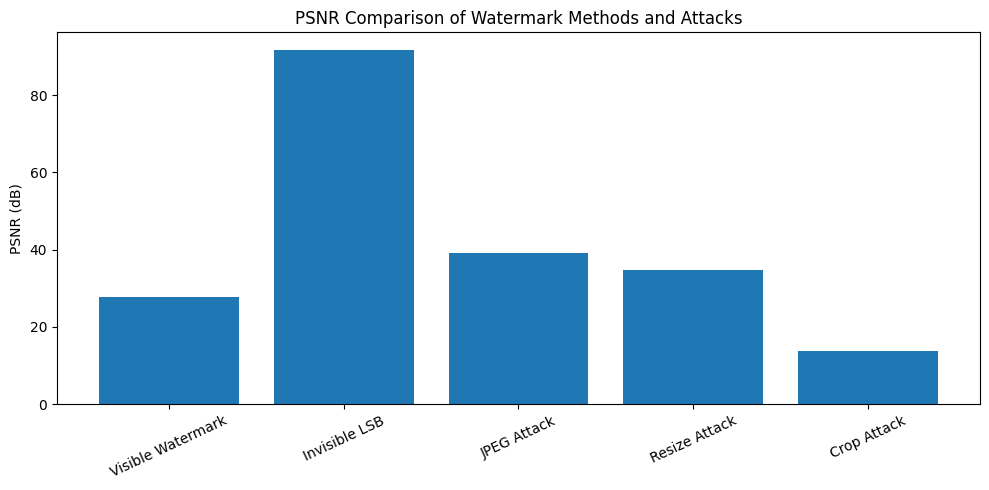

In [106]:
plt.figure(figsize=(10, 5))

plt.bar(
    watermark_results["Method"],
    watermark_results["PSNR (dB)"]
)

plt.title("PSNR Comparison of Watermark Methods and Attacks")
plt.ylabel("PSNR (dB)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

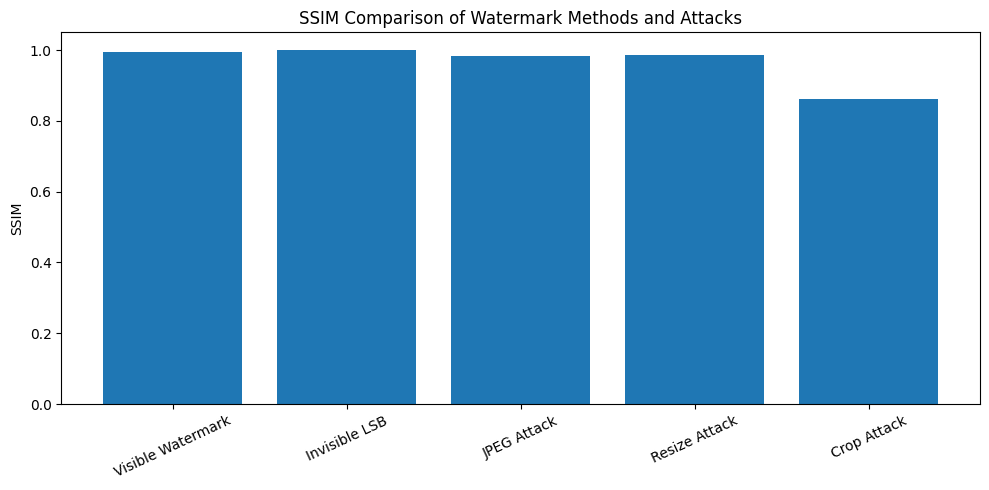

In [107]:
plt.figure(figsize=(10, 5))

plt.bar(
    watermark_results["Method"],
    watermark_results["SSIM"]
)

plt.title("SSIM Comparison of Watermark Methods and Attacks")
plt.ylabel("SSIM")
plt.xticks(rotation=25)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

In [108]:
print("WATERMARKING EXPERIMENT CONCLUSION")
print("---------------------------------")
print("Visible Watermark PSNR:", round(visible_psnr, 2), "dB")
print("Invisible LSB PSNR:", round(lsb_psnr, 2), "dB")
print("Invisible LSB SSIM:", round(lsb_ssim, 4))
print("JPEG Attack PSNR:", round(jpeg_psnr, 2), "dB")
print("Resize Attack PSNR:", round(resize_psnr, 2), "dB")
print("Crop Attack PSNR:", round(crop_psnr, 2), "dB")
print()
print("Invisible LSB watermark is highly imperceptible,")
print("but vulnerable to JPEG compression, resizing, and cropping.")
print("Visible watermark is easier to recognize,")
print("but causes noticeable pixel changes.")

WATERMARKING EXPERIMENT CONCLUSION
---------------------------------
Visible Watermark PSNR: 27.6 dB
Invisible LSB PSNR: 91.65 dB
Invisible LSB SSIM: 1.0
JPEG Attack PSNR: 39.12 dB
Resize Attack PSNR: 34.76 dB
Crop Attack PSNR: 13.68 dB

Invisible LSB watermark is highly imperceptible,
but vulnerable to JPEG compression, resizing, and cropping.
Visible watermark is easier to recognize,
but causes noticeable pixel changes.
